# What's Your Sign? — NFL Rosters by Zodiac

A dot matrix of every rostered player, grouped by position, across the twelve
zodiac signs — laid out in **calendar order** (Capricorn → Sagittarius) rather
than the traditional astrological ordering, so the x-axis reads left-to-right
the way a birthday calendar does.

**Source:** ESPN via `dataglazer_nfl.clients.espn.get_league_players`, pulled
live at run time — the zodiac sign is derived from each player's
`dateOfBirth` in `roster.py`, so it's only as complete as ESPN's birth-date
coverage.

This is a for-fun chart, not an analytical one: don't read causation into
whether Leos make good linebackers.

## Step 1 — Imports and the house style

`apply_style()` loads the shared `@dataglazer` stylesheet. This chart deviates
from it in one deliberate way: the base sheet uses bright white text on a
near-black grid, but the dot-matrix spec calls for the same muted blue-gray
(`#B7C4D2`) on **both** text and gridlines, for a quieter, more monochrome
read. `MUTED` already *is* that exact hex — `palette.py` parses it straight
off the stylesheet's `xtick.color` — so pulling it in and reassigning it to
the text/grid rcParams isn't a substitution, it's reusing the one value the
file already defines.

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dataglazer_nfl.clients import espn
from dataglazer_nfl.config import FIGURES_DIR, RAW_DATA_DIR
from dataglazer_nfl.viz.palette import BG, MUTED, SPINE, SURFACE
from dataglazer_nfl.viz.style import apply_style

apply_style()

# Dot-matrix spec: text AND gridlines in the same muted blue-gray, not the
# stylesheet's default white text / near-black grid.
for rc in ("text.color", "axes.labelcolor", "axes.titlecolor", "grid.color", "legend.labelcolor"):
    plt.rcParams[rc] = MUTED

# The style file's savefig.bbox is "tight", which silently re-crops whatever
# size you asked for. Force it back so the figsize below actually ships as
# the 1600x800 the spec wants.
plt.rcParams["savefig.bbox"] = "standard"

print(plt.rcParams["font.sans-serif"][:2], "|", BG, SURFACE, MUTED)

['Baloo 2', 'Poppins'] | #1F2831 #171E25 #B7C4D2


## Step 2 — Pull the league roster

One row per rostered player, league-wide (~3,000 rows). `zodiac` comes
pre-computed from `dateOfBirth`; it's `None` wherever ESPN has no birth date
on file.

In [50]:
# players = espn.get_league_players()
# get players from saved CSV file
players = pd.read_csv(RAW_DATA_DIR / "players.csv").to_dict(orient="records")
df = pd.DataFrame(players)
print(f"{len(df)} players loaded across the league")

2972 players loaded across the league


In [51]:
# Save the players for future analysis
# df.to_csv("players.csv", index=False)

## Step 3 — Drop unknown birth dates

A player with no `dateOfBirth` has no zodiac sign, not an unusual one — those
rows have to come out before any per-sign count means anything.

In [52]:
n_before = len(df)
df = df.dropna(subset=["zodiac"])
n_dropped = n_before - len(df)
print(f"Dropped {n_dropped} of {n_before} players with no birth date on record "
      f"({len(df)} remain).")

Dropped 14 of 2972 players with no birth date on record (2958 remain).


## Step 4 — Count each position x sign, in calendar order

`SIGN_ORDER` is the x-axis order the chart will use — calendar, not the
traditional Aries-first zodiac wheel. The table below is the sanity check:
every dot in the chart is one cell of this grid.

In [53]:
SIGN_ORDER = [
    "Capricorn", "Aquarius", "Pisces", "Aries", "Taurus", "Gemini",
    "Cancer", "Leo", "Virgo", "Libra", "Scorpio", "Sagittarius",
]

counts = (
    df.groupby(["position", "zodiac"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SIGN_ORDER, fill_value=0)
)
counts["TOTAL"] = counts.sum(axis=1)
# Sort by total desc for the legend order the spec asks for; alphabetical
# tie-break so equal totals (P and PK both land on 38) are reproducible
# rather than however the sort happened to leave them.
counts = counts.reset_index().sort_values(["TOTAL", "position"], ascending=[False, True]).set_index("position")
counts

zodiac,Capricorn,Aquarius,Pisces,Aries,Taurus,Gemini,Cancer,Leo,Virgo,Libra,Scorpio,Sagittarius,TOTAL
position,,,,,,,,,,,,,
LB,32,34,44,38,32,34,29,33,35,35,27,35,408
WR,29,27,35,38,36,29,24,30,31,31,30,41,381
CB,30,25,29,28,24,18,27,22,43,29,23,35,333
DT,15,17,25,23,31,16,21,23,22,34,27,18,272
S,11,30,16,18,19,24,24,11,22,20,22,17,234
OT,26,18,20,29,23,15,13,27,12,23,12,14,232
TE,15,17,17,17,16,10,19,17,22,20,17,15,202
RB,21,22,15,16,15,16,7,15,20,19,13,15,194
G,20,20,16,15,12,17,14,16,22,14,12,6,184


## Step 5 — Color per position, and deterministic jitter

**Color.** Sixteen-plus categories in one all-pairs scatter is past what any
fixed hue order can keep pairwise-distinct — sixteen equally spaced hues are
only ~22° apart, well under a comfortable separation. `zigzag()` doesn't fix
that ceiling, it just decides *which* positions end up as neighbors on the
hue wheel: interleaving from both ends of the total-count ranking means a
high-count position's closest hue neighbor is a rare one (LB next to the
one-player DL, not next to WR), so the two positions people actually see
side by side most often stay the most distinguishable.

**Jitter.** Every dot's x is `sign index + a per-position offset`, so
same-count dots at the same sign don't stack exactly on top of each other.
The offset is drawn once from a seeded `Generator` — reproducible across
re-runs — and fixed per position (not re-rolled per sign), so a position
occupies the same little "lane" in every column. Y values are never
touched.

In [54]:
import math


def oklch_to_hex(L, C, hue_deg):
    """OKLCH -> sRGB hex, so hues can be spaced evenly by eye rather than eyeballed."""
    h = math.radians(hue_deg)
    a, b = C * math.cos(h), C * math.sin(h)
    l_, m_, s_ = (
        L + 0.3963377774 * a + 0.2158037573 * b,
        L - 0.1055613458 * a - 0.0638541728 * b,
        L - 0.0894841775 * a - 1.2914855480 * b,
    )
    l, m, s = l_**3, m_**3, s_**3
    r = 4.0767416621 * l - 3.3077115913 * m + 0.2309699292 * s
    g = -1.2684380046 * l + 2.6097574011 * m - 0.3413193965 * s
    bl = -0.0041960863 * l - 0.7034186147 * m + 1.7076147010 * s

    def to_srgb(c):
        c = max(0.0, min(1.0, c))
        return c * 12.92 if c <= 0.0031308 else 1.055 * c ** (1 / 2.4) - 0.055

    r, g, bl = (to_srgb(c) for c in (r, g, bl))
    return "#%02X%02X%02X" % (round(r * 255), round(g * 255), round(bl * 255))


def zigzag(seq):
    """[highest, lowest, 2nd-highest, 2nd-lowest, ...] — see markdown above."""
    out, lo, hi = [], 0, len(seq) - 1
    while lo <= hi:
        out.append(seq[lo])
        lo += 1
        if lo <= hi:
            out.append(seq[hi])
            hi -= 1
    return out


positions = counts.index.tolist()  # legend order: total desc, per the spec
n_pos = len(positions)

hue_order = zigzag(positions)
palette = [oklch_to_hex(L=0.60, C=0.135, hue_deg=i * 360 / n_pos) for i in range(n_pos)]
color_of = dict(zip(hue_order, palette))

JITTER_SEED = 42
JITTER_WIDTH = 0.32  # signs are 1 unit apart; this leaves clear space before the next one
rng = np.random.default_rng(JITTER_SEED)
# Fixed alphabetical order for the draw itself, so the seed maps to the same
# offsets regardless of what order `positions` (total-desc) happens to be in.
alpha_order = sorted(positions)
jitter_of = dict(zip(alpha_order, rng.uniform(-JITTER_WIDTH, JITTER_WIDTH, size=n_pos)))

## Step 6 — Build the dot matrix

One `scatter` call per position — its 12 counts across `SIGN_ORDER` — plotted
at `sign index + jitter`. That keeps every position's dots a single labelled
artist, so the legend needs no proxy handles.

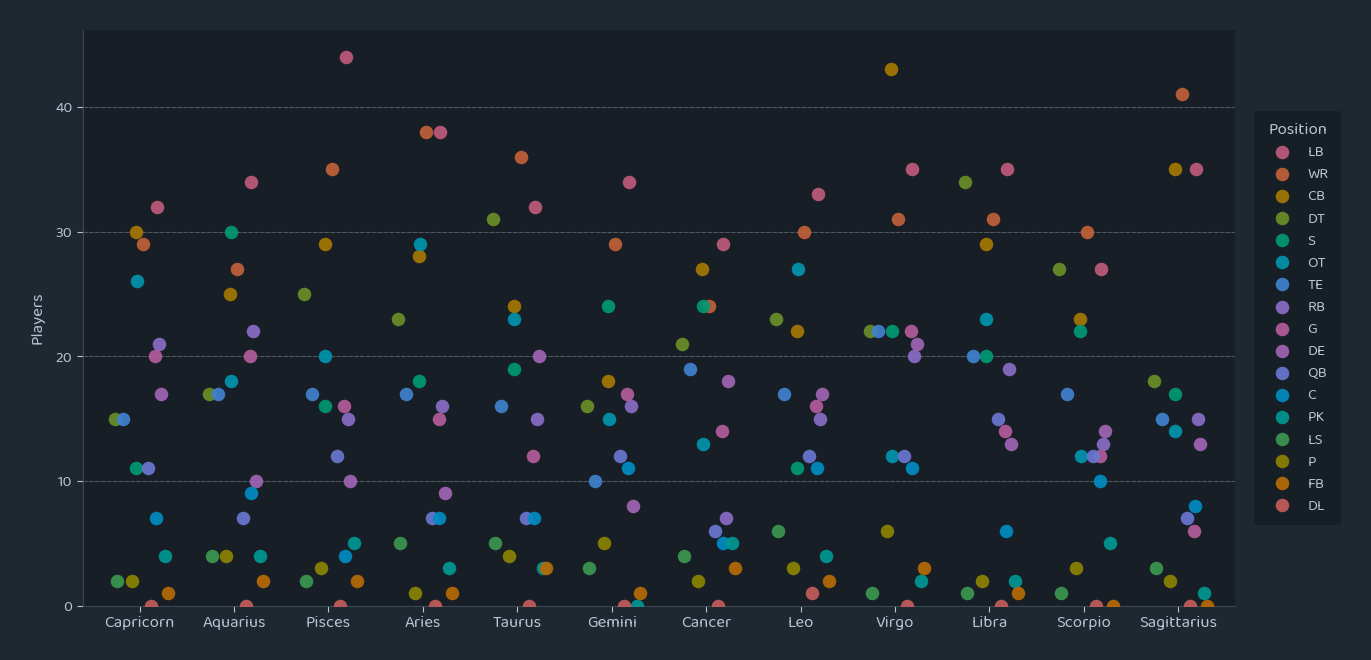

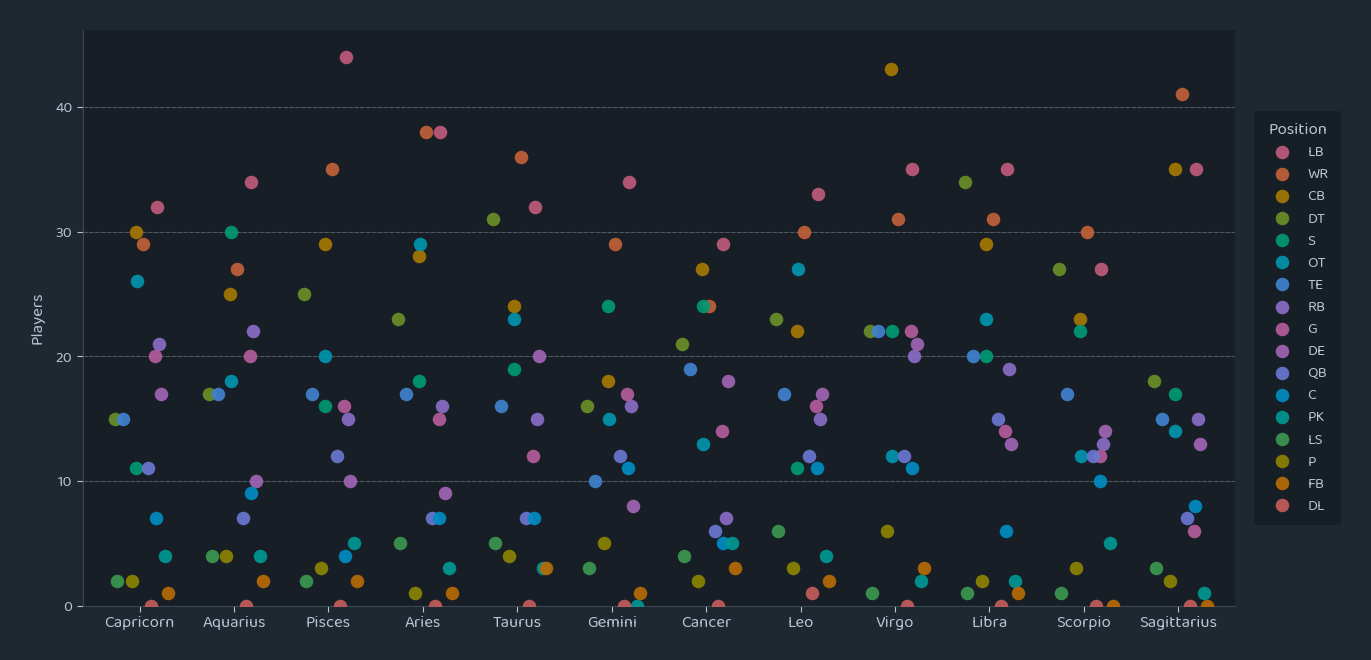

In [55]:
fig, ax = plt.subplots(figsize=(16, 8))  # 1600x800 at dpi=100
fig.subplots_adjust(left=0.055, right=0.775, top=0.83, bottom=0.11)
ax.set_facecolor(SURFACE)

x = np.arange(len(SIGN_ORDER))
for pos in positions:
    y = counts.loc[pos, SIGN_ORDER].to_numpy()
    ax.scatter(x + jitter_of[pos], y, s=95, color=color_of[pos], label=pos, alpha=0.92, zorder=3)

ax.set_xlim(-0.6, len(SIGN_ORDER) - 1 + 0.6)
ax.set_xticks(x)
ax.set_xticklabels(SIGN_ORDER, fontsize=12)
ax.set_ylim(bottom=0)
ax.set_ylabel("Players", fontsize=12)

# The stylesheet grids on x by default; this chart wants horizontal-only.
ax.grid(axis="y", visible=True, alpha=0.35)
ax.grid(axis="x", visible=False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_color(SPINE)

# Legend order matches `positions`: total descending, per the spec.
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
leg = ax.legend(
    [by_label[p] for p in positions], positions,
    loc="center left", bbox_to_anchor=(1.01, 0.5),
    frameon=True, facecolor=SURFACE, edgecolor=SPINE,
    labelcolor=MUTED, fontsize=11, borderpad=0.8, labelspacing=0.55,
    handletextpad=0.7, title="Position", title_fontsize=12,
)
leg.get_title().set_color(MUTED)

fig

## Step 7 — Title and subtitle

Just the two lines the spec calls for: a title, and a subtitle carrying the
roster snapshot date plus the unknown-birth-date count from Step 3. No
footnote, caption, or watermark. Centered over the plot area (not the full
1600px canvas), since the legend gutter would otherwise pull it visibly
off-center from the data.

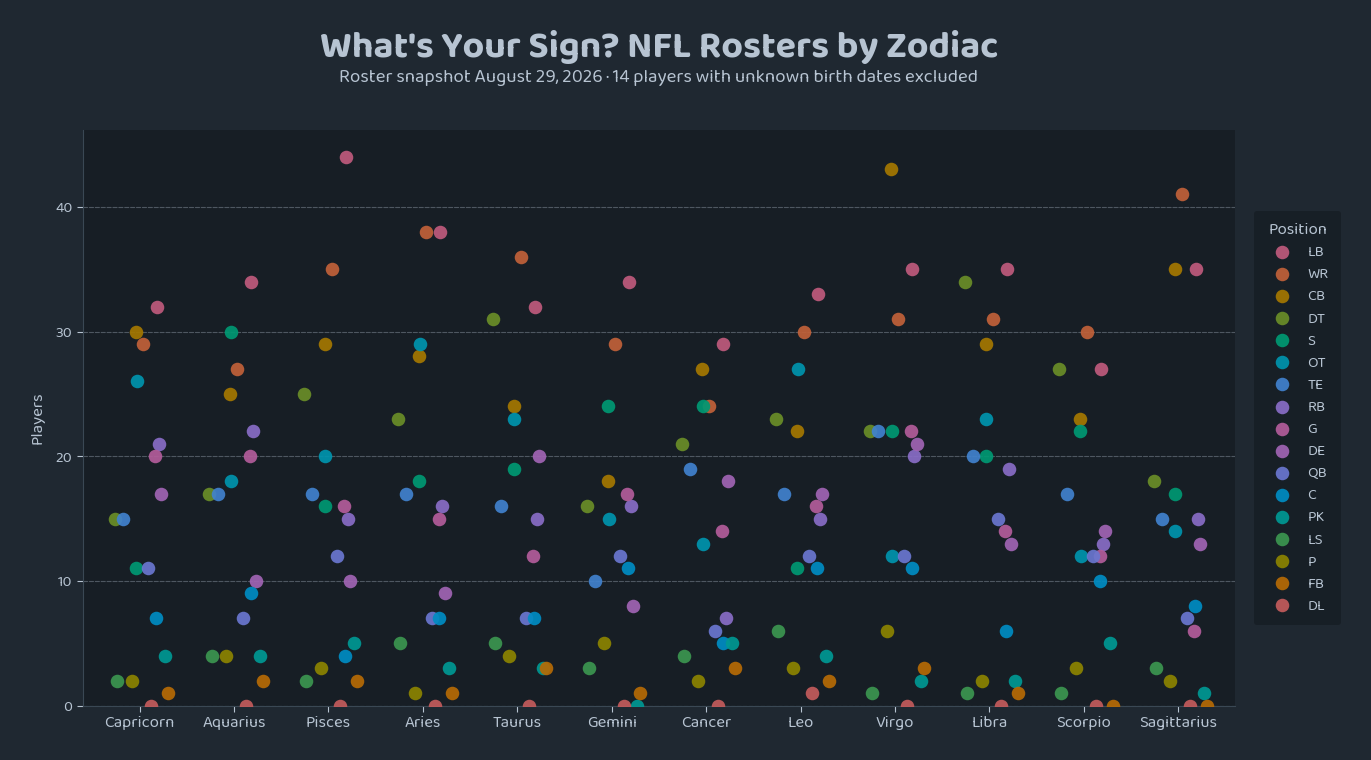

In [56]:
from datetime import date

plot_left, plot_right = 0.055, 0.775
title_x = (plot_left + plot_right) / 2
snapshot_date = date.today().strftime("%B %d, %Y")

fig.text(title_x, 0.955, "What's Your Sign? NFL Rosters by Zodiac",
          ha="center", va="top", fontsize=27, fontweight="bold", color=MUTED)
fig.text(title_x, 0.905,
          f"Roster snapshot {snapshot_date} · {n_dropped} players with unknown birth dates excluded",
          ha="center", va="top", fontsize=13.5, color=MUTED)

fig

## Step 8 — Save

`facecolor=BG` matches the figure background explicitly, on top of the
`savefig.facecolor` rcParam, the same belt-and-suspenders the other
dataglazer notebooks use.

In [57]:
out = FIGURES_DIR / "position-zodiac-dot-matrix.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=100, facecolor=BG)
print(f"saved -> {out.name}  ({out.stat().st_size / 1024:.0f} KB)")

saved -> position-zodiac-dot-matrix.png  (93 KB)


## Step 9 — Within-position share of each sign

A different question than the dot matrix above: not "how many Leos play
each position" but **"of all QBs, what share are Leos"** — i.e. normalize
each position's row of `counts` by its own total, so every position's bars
sum to 100% across the twelve signs. Restricted to seven positions
(`QB, WR, CB, TE, RB, S, DE`) so the bars stay legible at seven-per-cluster.

In [58]:
BAR_POSITIONS = [p for p in positions if p in {"QB", "WR", "CB", "TE", "RB", "S", "DE"}]

share = counts.loc[BAR_POSITIONS, SIGN_ORDER].div(counts.loc[BAR_POSITIONS, "TOTAL"], axis=0) * 100
share.round(1)

zodiac,Capricorn,Aquarius,Pisces,Aries,Taurus,Gemini,Cancer,Leo,Virgo,Libra,Scorpio,Sagittarius
position,,,,,,,,,,,,
WR,7.6,7.1,9.2,10.0,9.4,7.6,6.3,7.9,8.1,8.1,7.9,10.8
CB,9.0,7.5,8.7,8.4,7.2,5.4,8.1,6.6,12.9,8.7,6.9,10.5
S,4.7,12.8,6.8,7.7,8.1,10.3,10.3,4.7,9.4,8.5,9.4,7.3
TE,7.4,8.4,8.4,8.4,7.9,5.0,9.4,8.4,10.9,9.9,8.4,7.4
RB,10.8,11.3,7.7,8.2,7.7,8.2,3.6,7.7,10.3,9.8,6.7,7.7
DE,10.0,5.9,5.9,5.3,11.8,4.7,10.6,10.0,12.4,7.6,8.2,7.6
QB,9.2,5.8,10.0,5.8,5.8,10.0,5.0,10.0,10.0,12.5,10.0,5.8


## Step 10 — Colors for seven series, side by side

The dot matrix's 17-way palette can't be reused here: it was built (via
`zigzag`) to keep only the *highest-count* positions apart, and three of
these seven — QB, RB, TE — happened to land in adjacent blue-violet hue
slots there. Since a grouped bar chart only ever puts *neighboring* bars
side by side (never all seven at once, the way every dot matrix color can
sit next to any other), the dataviz house palette's standard 8-hue order
is the right tool here — it's validated against exactly that "adjacent
pairs" bar-chart case, not the harder all-pairs case the scatter needed.

In [59]:
# @dataglazer categorical theme, dark-mode steps, in its fixed order —
# validated (worst adjacent CVD deltaE 8.4, normal-vision 19.3) against
# this chart's #171E25 surface for the adjacent-only case a grouped bar
# chart actually needs.
BAR_THEME = ["#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9"]
bar_color_of = dict(zip(BAR_POSITIONS, BAR_THEME))

## Step 11 — Grouped bar chart

Seven bars per sign, one cluster per sign, `BAR_POSITIONS` order held fixed
across every cluster. The natural baseline for reading "is this position's
Leo share actually high" isn't an even 1/12 split — birth rates aren't flat
across the calendar — so the real reference line, built from actual US
natality data (Step 13), gets overlaid once that data is available.

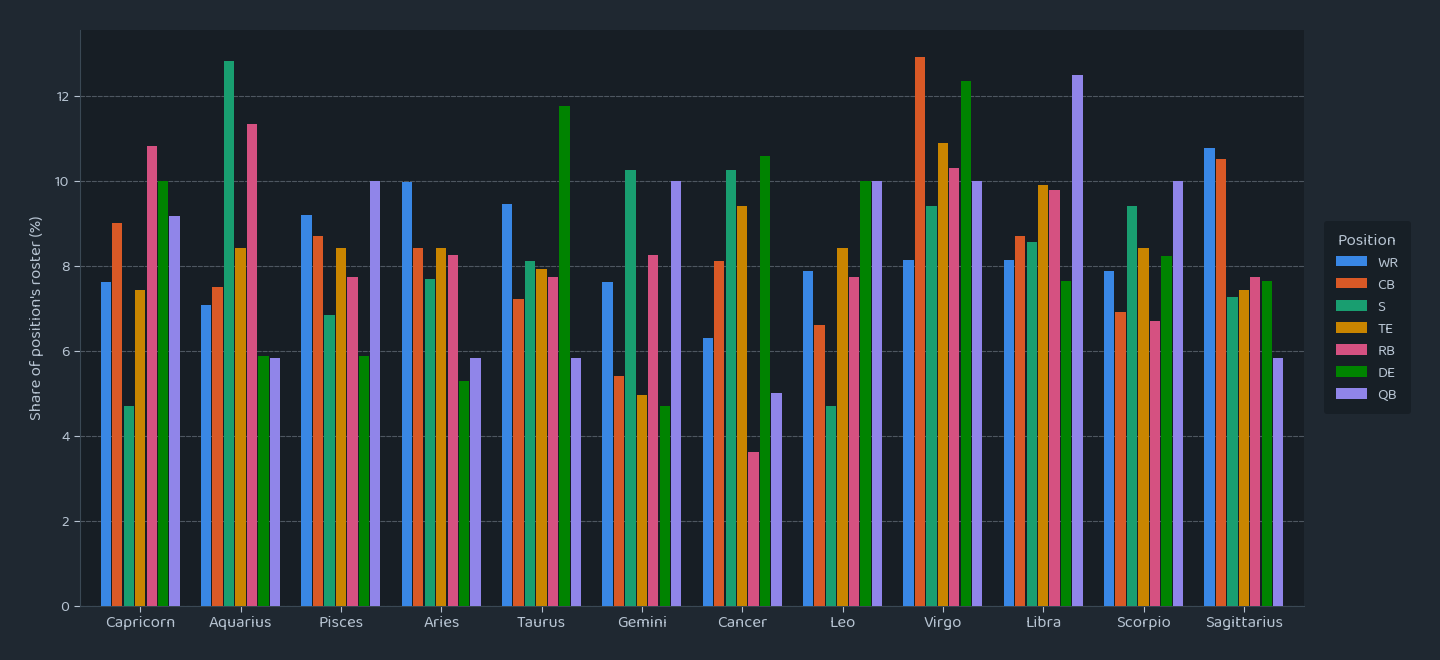

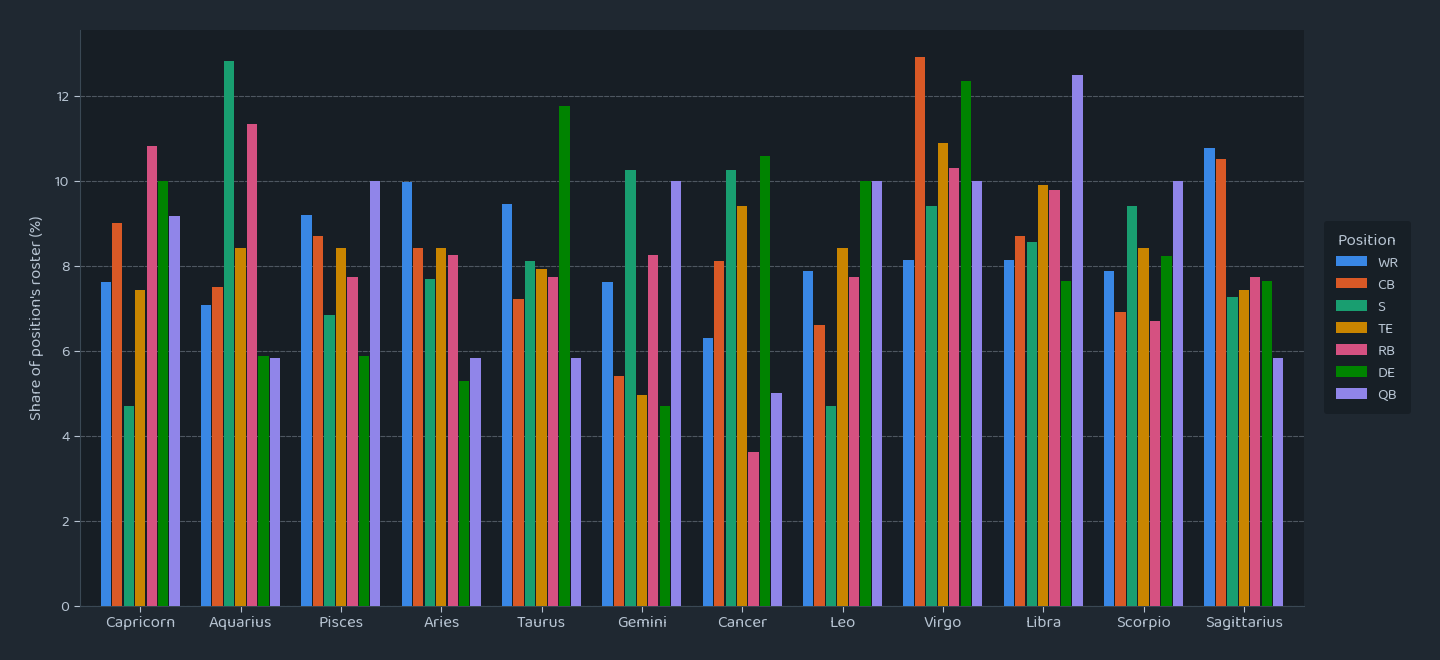

In [60]:
fig, ax = plt.subplots(figsize=(16, 8))  # 1600x800 at dpi=100
fig.subplots_adjust(left=0.055, right=0.82, top=0.83, bottom=0.11)
ax.set_facecolor(SURFACE)

n_bars = len(BAR_POSITIONS)
x = np.arange(len(SIGN_ORDER))
width = 0.8 / n_bars

bars = []
for i, pos in enumerate(BAR_POSITIONS):
    offset = (i - (n_bars - 1) / 2) * width
    b = ax.bar(x + offset, share.loc[pos, SIGN_ORDER], width=width * 0.9,
               color=bar_color_of[pos], label=pos, zorder=3)
    bars.append(b)

# Used later (Step 14) as the deviation baseline; the even-split reference
# line itself is added in Step 13 once real birth-rate data is available.
even_split = 100 / len(SIGN_ORDER)

ax.set_xlim(-0.6, len(SIGN_ORDER) - 1 + 0.6)
ax.set_xticks(x)
ax.set_xticklabels(SIGN_ORDER, fontsize=12)
ax.set_ylim(bottom=0)
ax.set_ylabel("Share of position's roster (%)", fontsize=12)

ax.grid(axis="y", visible=True, alpha=0.35)
ax.grid(axis="x", visible=False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_color(SPINE)

leg = ax.legend(
    bars, BAR_POSITIONS,
    loc="center left", bbox_to_anchor=(1.01, 0.5),
    frameon=True, facecolor=SURFACE, edgecolor=SPINE,
    labelcolor=MUTED, fontsize=11, borderpad=0.8, labelspacing=0.55,
    handletextpad=0.7, title="Position", title_fontsize=12,
)
leg.get_title().set_color(MUTED)

fig

# Step 12 - Natality data - Approximate US population by Zodiac ratio
Use the CDC births by month data and Zodiac date cut offs to approximate the proportion of each Zodiac sign within the US population

In [61]:
birth_data = pd.read_csv(RAW_DATA_DIR / "Natality, 2003-2006.csv")
births = birth_data[["Month","Births"]].copy()
births.head()

,Month,Births
0,January,1334485.0
1,February,1251924.0
2,March,1389375.0
3,April,1325727.0
4,May,1386118.0


<Axes: >

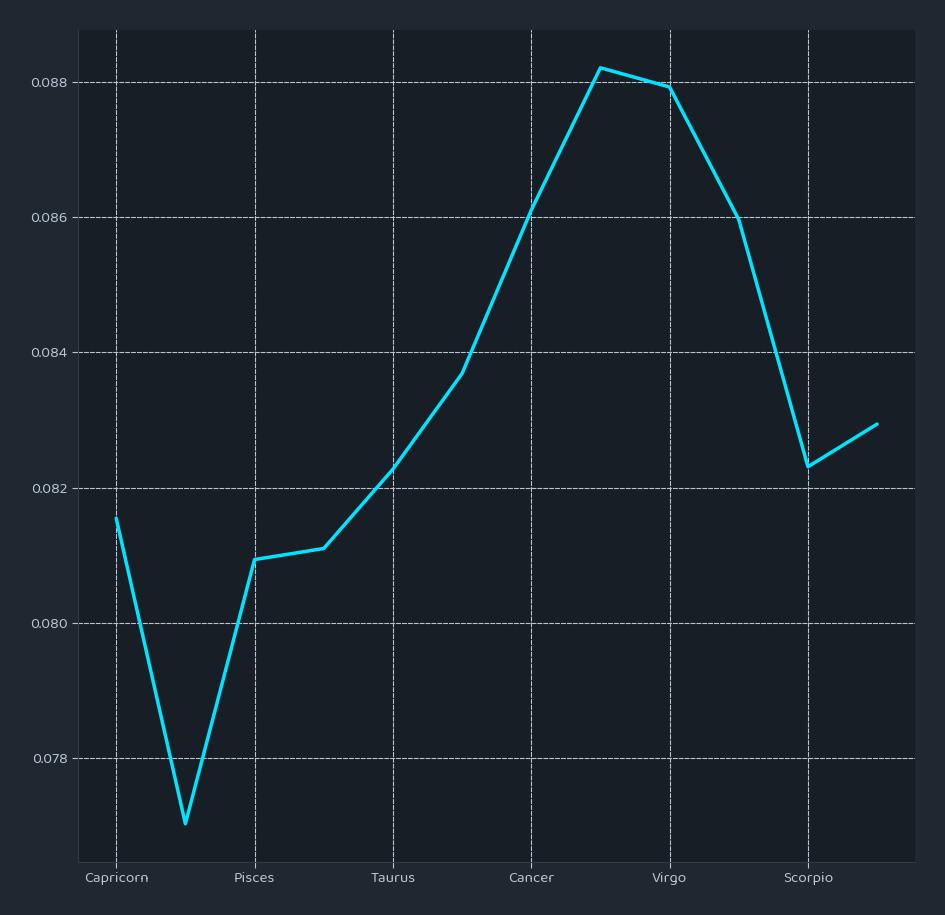

In [62]:
# set up a dictionary representing the proportion of each month
# belonging to each zodiac sign
zodiac_proportions = {
    "January": {"Capricorn": 0.67, "Aquarius": 0.33},
    "February": {"Aquarius": 0.67, "Pisces": 0.33},
    "March": {"Pisces": 0.67, "Aries": 0.33},
    "April": {"Aries": 0.67, "Taurus": 0.33},
    "May": {"Taurus": 0.67, "Gemini": 0.33},
    "June": {"Gemini": 0.67, "Cancer": 0.33},
    "July": {"Cancer": 0.67, "Leo": 0.33},
    "August": {"Leo": 0.67, "Virgo": 0.33},
    "September": {"Virgo": 0.67, "Libra": 0.33},
    "October": {"Libra": 0.67, "Scorpio": 0.33},
    "November": {"Scorpio": 0.67, "Sagittarius": 0.33},
    "December": {"Sagittarius": 0.67, "Capricorn": 0.33},
}

# create a new DataFrame to store the estimated number of births for each zodiac sign
zodiac_births = pd.DataFrame(0.0, index=births.index, columns=[
    "Capricorn", "Aquarius", "Pisces", "Aries", "Taurus", "Gemini",
    "Cancer", "Leo", "Virgo", "Libra", "Scorpio", "Sagittarius"
])

# estimate the number of births for each zodiac sign
for month, proportions in zodiac_proportions.items():
    month_mask = births["Month"] == month
    for zodiac, proportion in proportions.items():
        zodiac_births.loc[month_mask, zodiac] = births.loc[month_mask, "Births"] * proportion

# display the estimated number of births for each zodiac sign
zodiac_births.head()

# display the total estimated number of births for each zodiac sign
zodiac_births.sum()

# normalize the total estimated number of births for each zodiac sign
zodiac_births_normalized = zodiac_births.sum() / zodiac_births.sum().sum()

# display the total estimated number of births for each zodiac sign as a bar plot
zodiac_births_normalized.plot(kind="line")


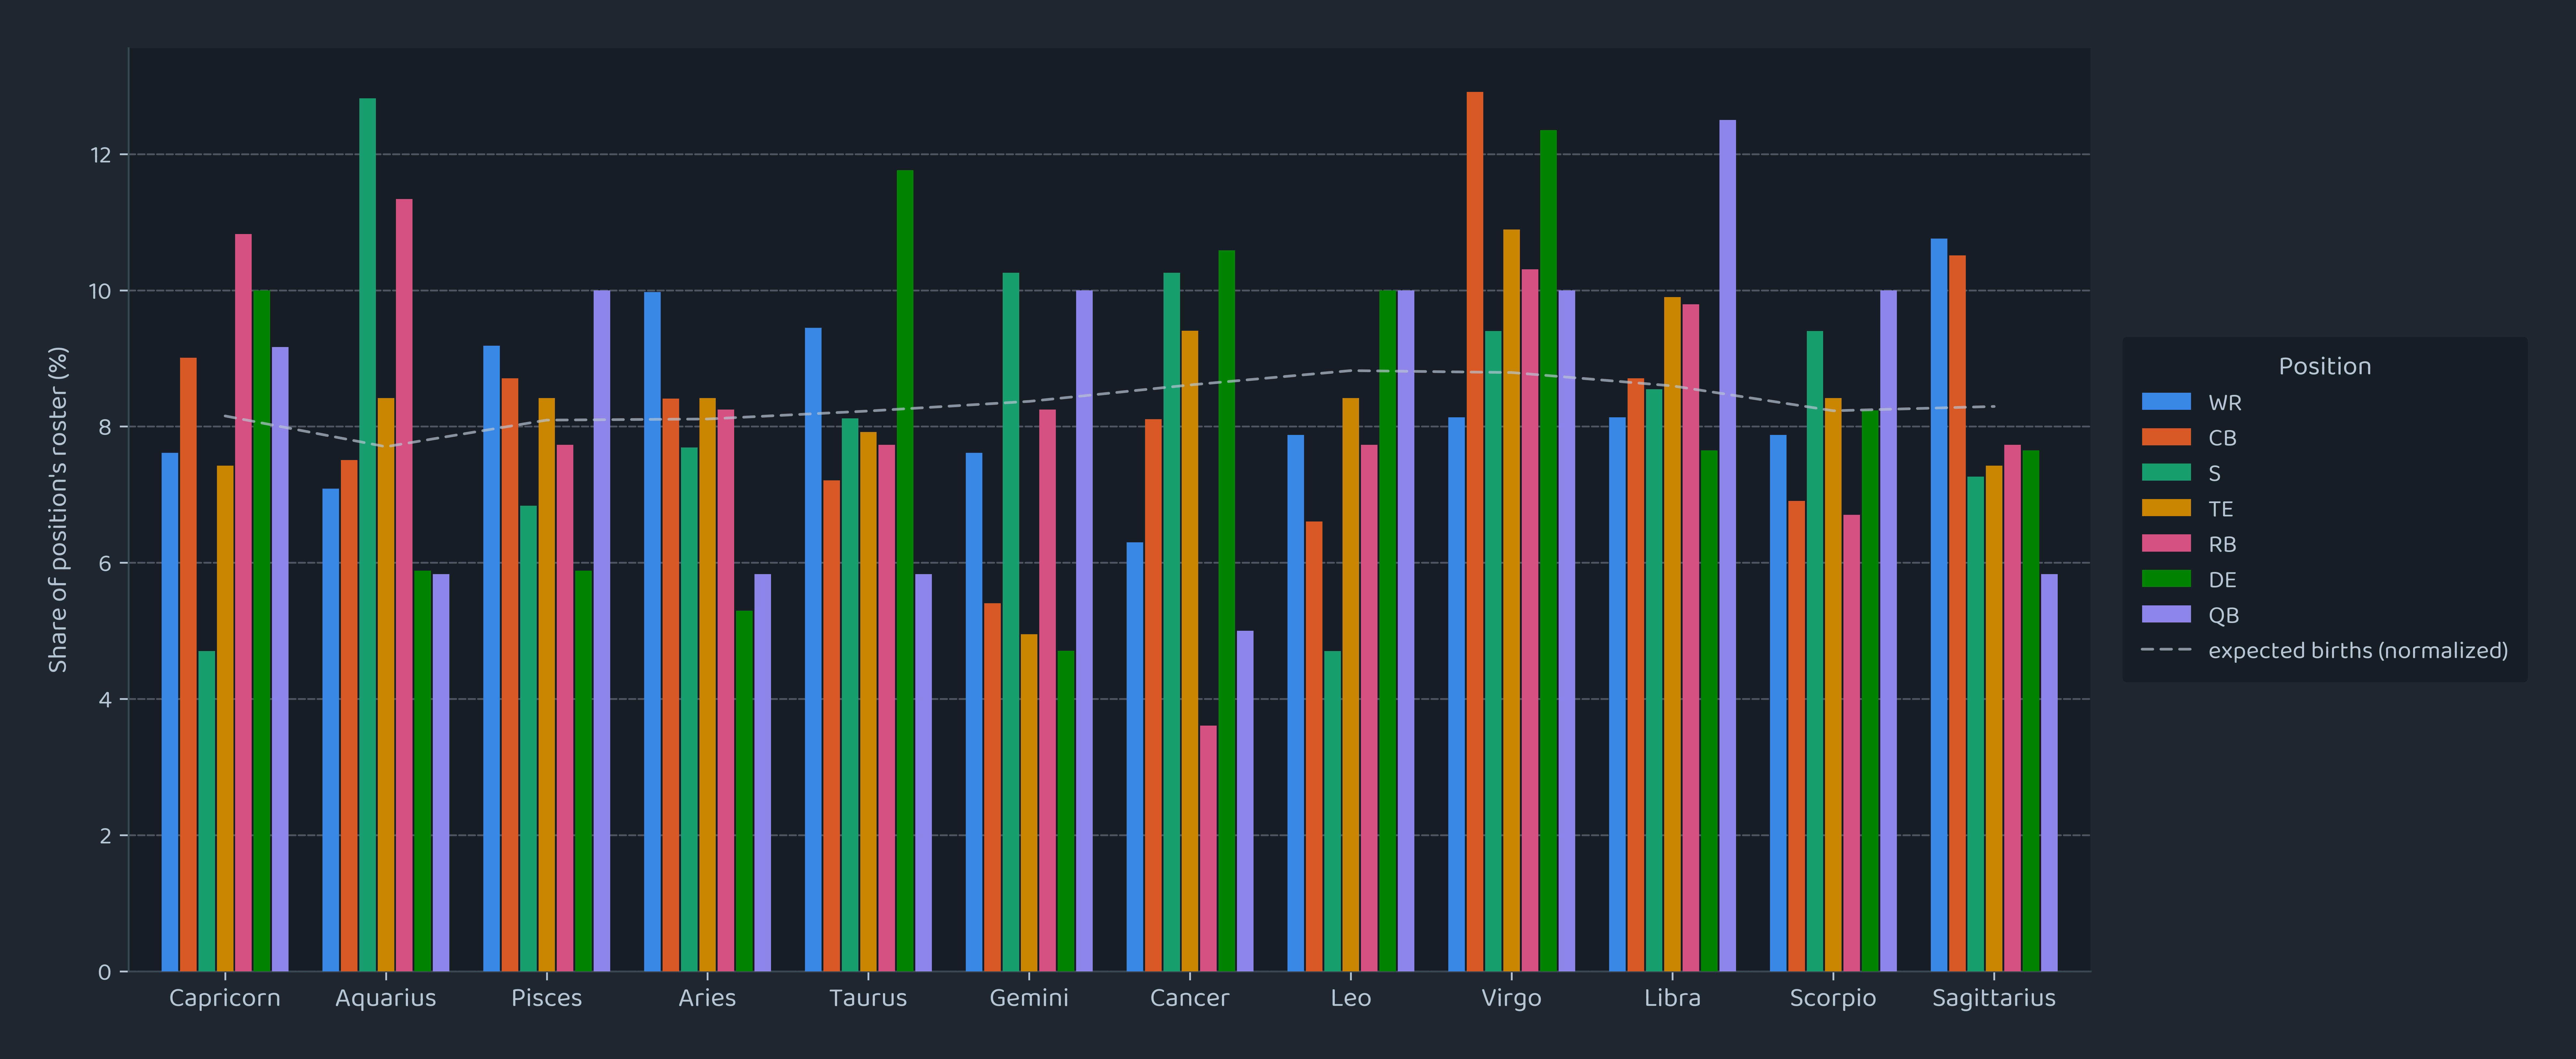

In [63]:
# overlay the normalized total estimated births for each sign, as the
# real reference line, over the grouped bar chart from Step 11 — replacing
# the naive 1/12 even-split baseline
x = zodiac_births_normalized.index
expected_share = zodiac_births_normalized * 100  # match the bars' % scale

true_ref_line, = ax.plot(
    x,
    expected_share.to_numpy(),
    color=MUTED,
    linewidth=1.2,
    linestyle=(0, (4, 3)),
    alpha=0.7,
    zorder=4,
    label="Expected births (normalized)",
)

leg = ax.legend(
    [*bars, true_ref_line], [*BAR_POSITIONS, "expected births (normalized)"],
    loc="center left", bbox_to_anchor=(1.01, 0.5),
    frameon=True, facecolor=SURFACE, edgecolor=SPINE,
    labelcolor=MUTED, fontsize=11, borderpad=0.8, labelspacing=0.55,
    handletextpad=0.7, title="Position", title_fontsize=12,
)
leg.get_title().set_color(MUTED)

fig.dpi=600
fig

In [64]:
out = FIGURES_DIR / "position-zodiac-deviation.png"
fig.savefig(out, dpi=600, facecolor=BG)
print(f"saved -> {out.name}  ({out.stat().st_size / 1024:.0f} KB)")

saved -> position-zodiac-deviation.png  (434 KB)


## Step 14 — Deviation from expected

Same `share` table as the bar chart, recast as a signed deviation from
`expected_share` — the real zodiac-birth-rate baseline from Step 13, not a
naive 1/12 even split. Positive means over-represented relative to how
common that sign is among births generally, negative means
under-represented, in percentage points.

In [65]:
deviation = share - expected_share.reindex(SIGN_ORDER)
deviation.round(1)

zodiac,Capricorn,Aquarius,Pisces,Aries,Taurus,Gemini,Cancer,Leo,Virgo,Libra,Scorpio,Sagittarius
position,,,,,,,,,,,,
WR,-0.5,-0.6,1.1,1.9,1.2,-0.8,-2.3,-0.9,-0.7,-0.5,-0.4,2.5
CB,0.9,-0.2,0.6,0.3,-1.0,-3.0,-0.5,-2.2,4.1,0.1,-1.3,2.2
S,-3.5,5.1,-1.3,-0.4,-0.1,1.9,1.6,-4.1,0.6,-0.0,1.2,-1.0
TE,-0.7,0.7,0.3,0.3,-0.3,-3.4,0.8,-0.4,2.1,1.3,0.2,-0.9
RB,2.7,3.6,-0.4,0.1,-0.5,-0.1,-5.0,-1.1,1.5,1.2,-1.5,-0.6
DE,1.8,-1.8,-2.2,-2.8,3.5,-3.7,2.0,1.2,3.6,-0.9,0.0,-0.6
QB,1.0,-1.9,1.9,-2.3,-2.4,1.6,-3.6,1.2,1.2,3.9,1.8,-2.5


## Step 15 — A red/white/cyan diverging scale, centered on zero

`RED` and `CYAN` are the same two hexes already in the stylesheet's
`axes.prop_cycle` (`#FF4444`, `#00E5FF`) — no new palette, just the brand's
existing negative/positive pair, run through a custom
`LinearSegmentedColormap` with white at the midpoint instead of the neutral
gray a "real" diverging palette would default to.

`TwoSlopeNorm` is what actually pins zero to white: the deviations aren't
symmetric around zero, so a plain linear norm across `[min, max]` would put
zero somewhere other than the colormap's midpoint. `TwoSlopeNorm(vcenter=0)`
maps `vmin -> 0.0`, `0 -> 0.5`, `vmax -> 1.0` regardless of how lopsided
`vmin`/`vmax` are, so zero deviation is always exactly white.

In [66]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from dataglazer_nfl.viz.palette import CYAN, RED

diverging_cmap = LinearSegmentedColormap.from_list("dataglazer_diverging", [RED, "#FFFFFF", CYAN])
max_abs = deviation.abs().to_numpy().max()
diverging_norm = TwoSlopeNorm(vmin=-max_abs, vcenter=0.0, vmax=max_abs)

## Step 16 — Build the heatmap

Cell text color is chosen per-cell from the resolved fill color's
luminance, not fixed — the scale runs from a fairly light red through
white to a very bright cyan, so a single text color would go unreadable
against one end or the other.

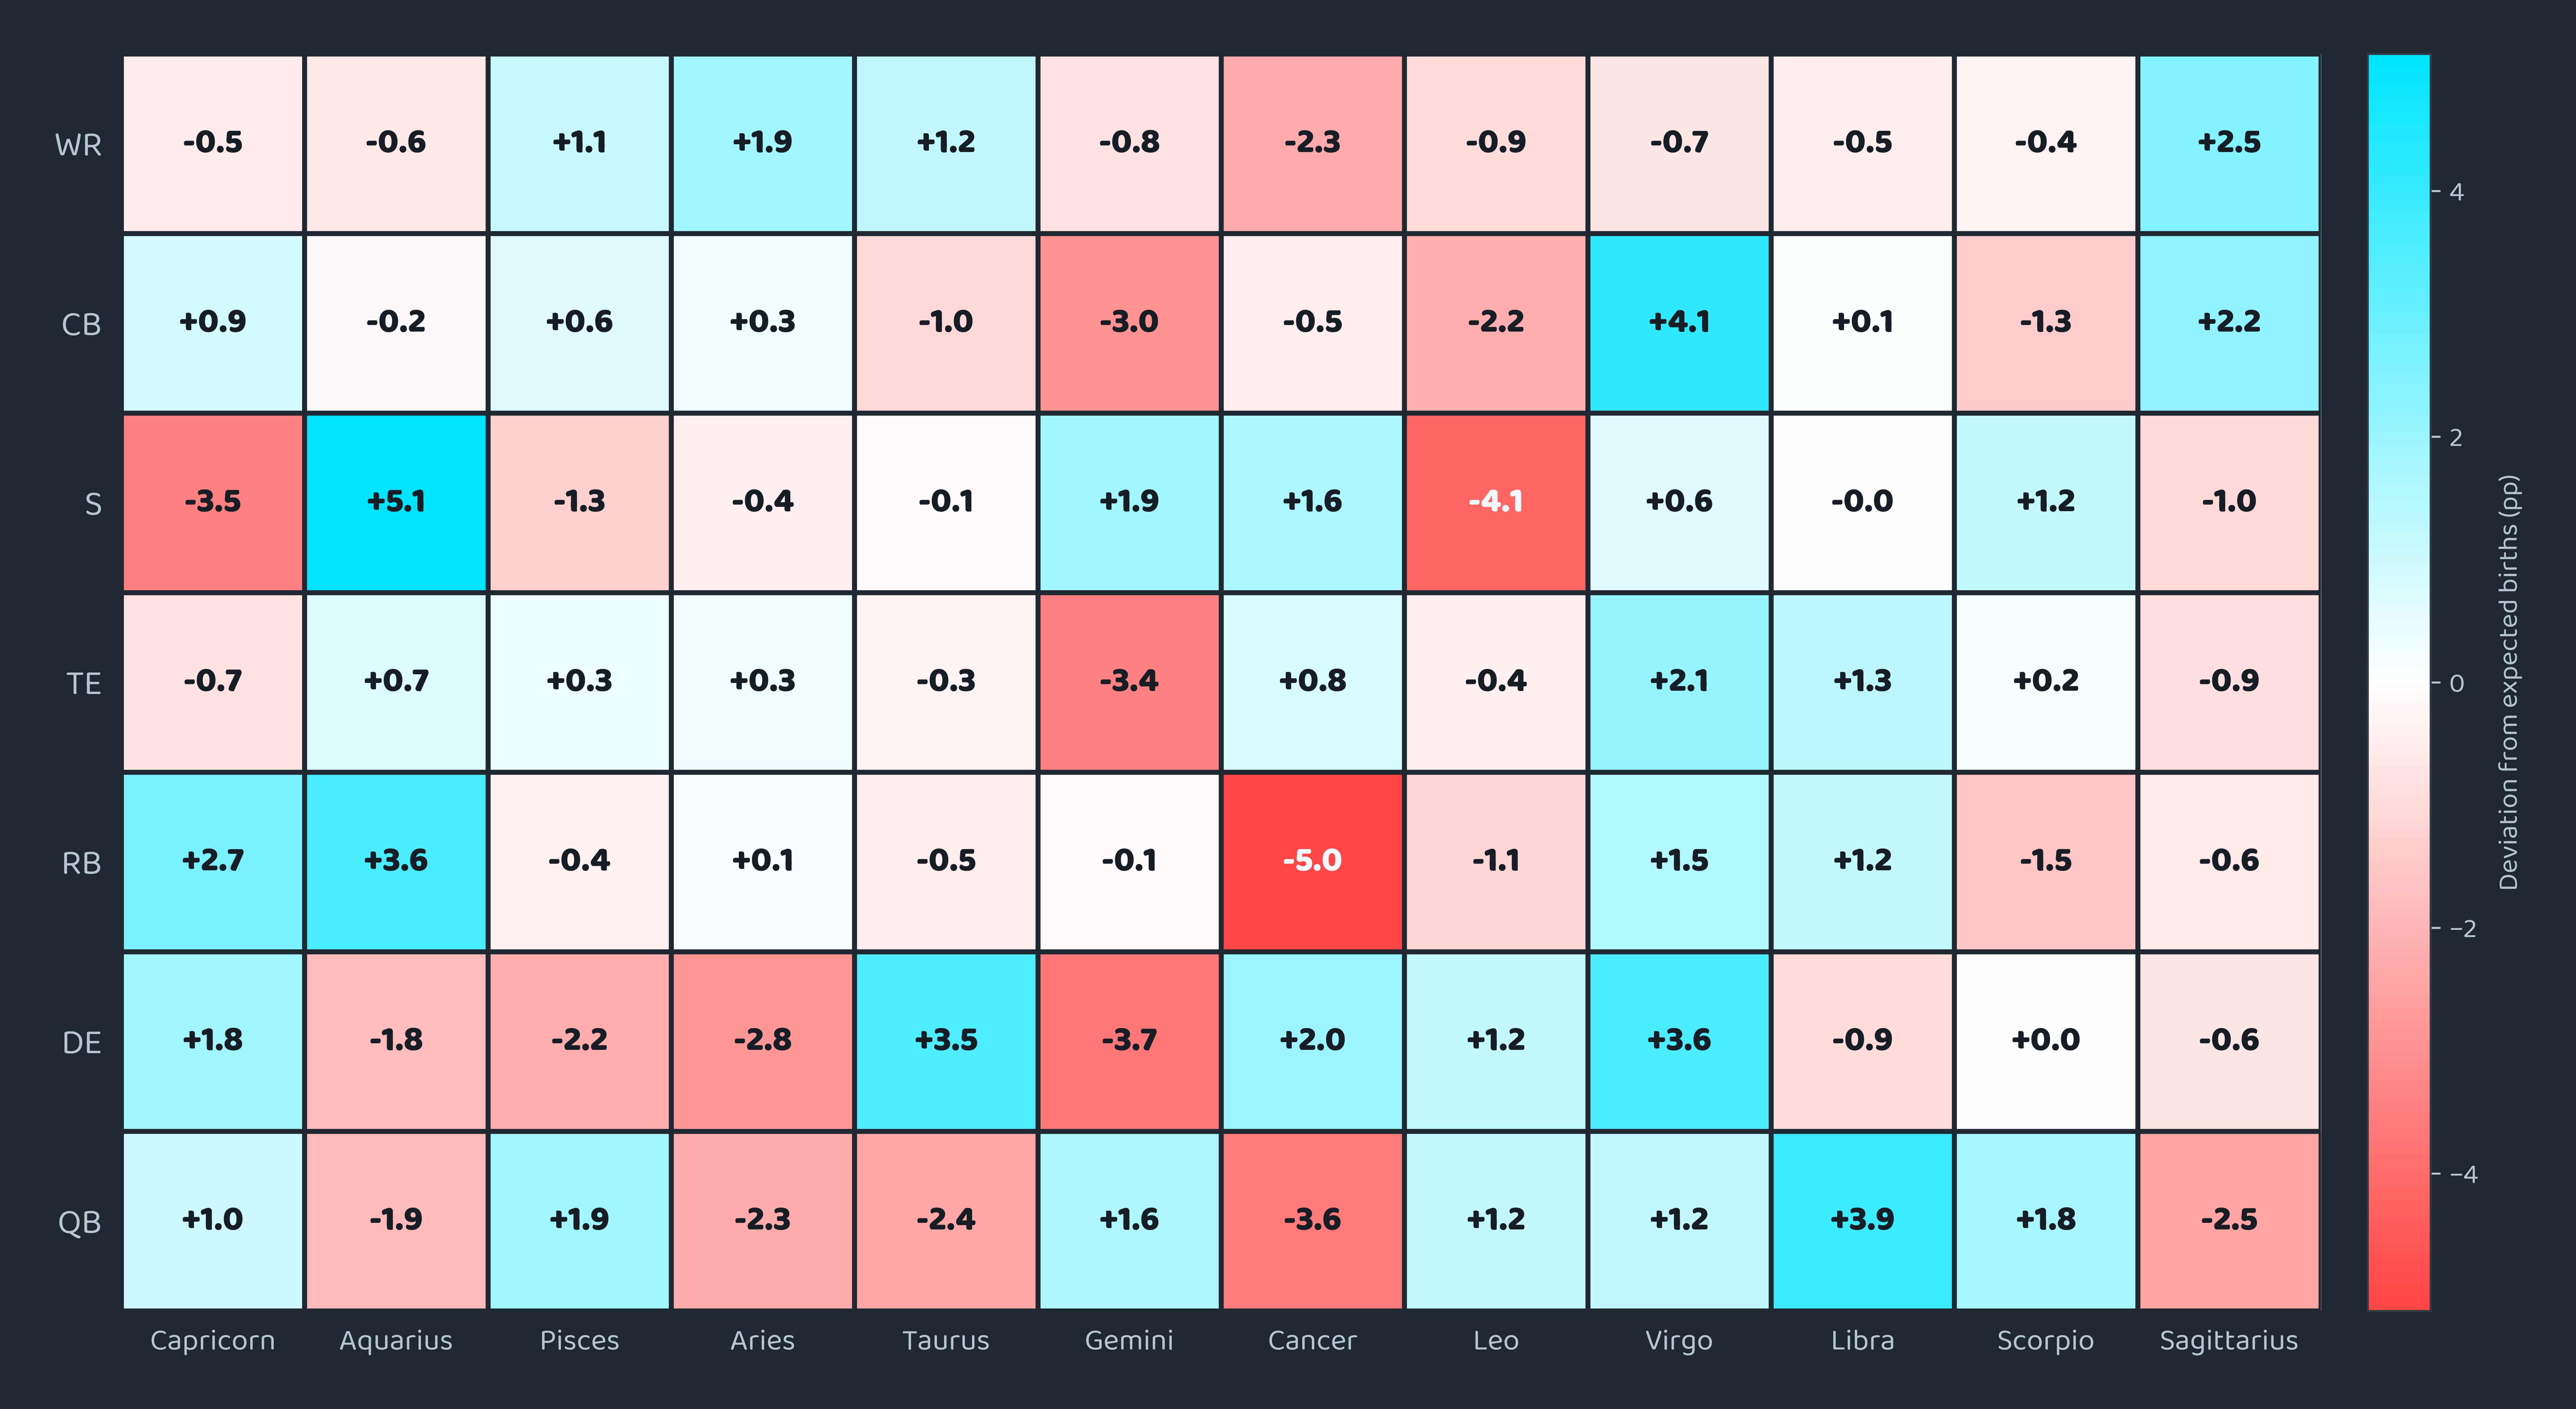

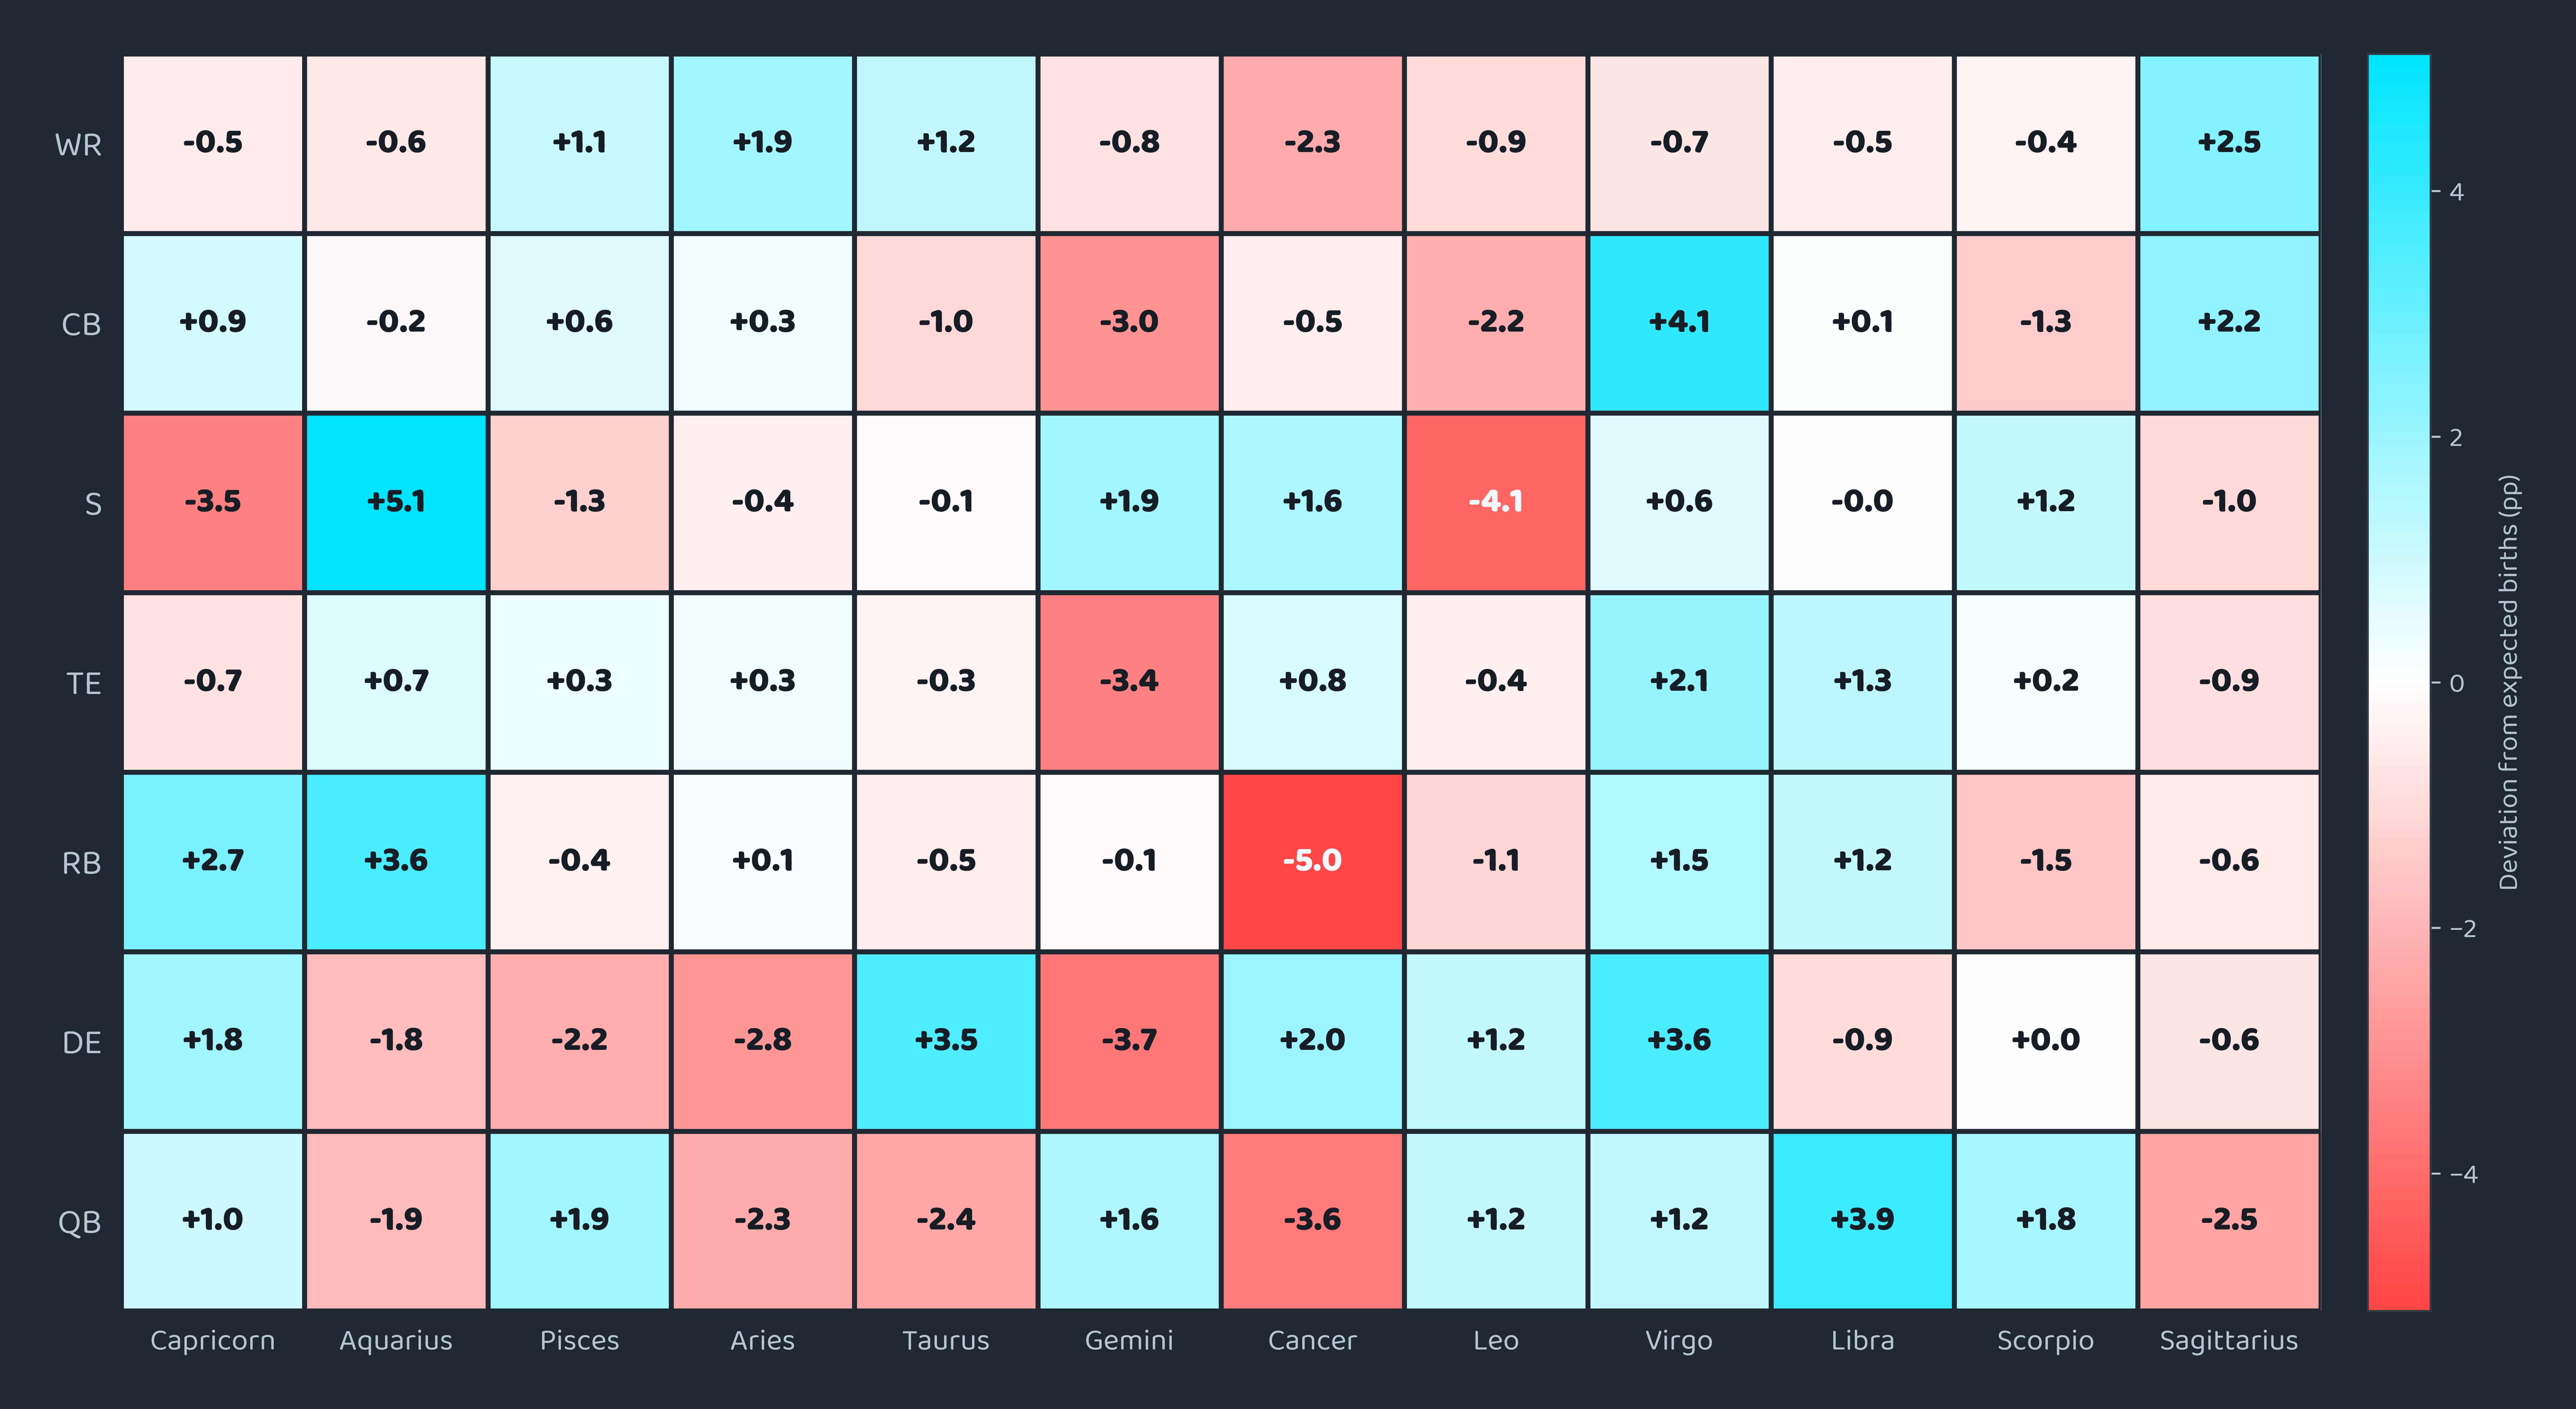

In [67]:
fig, ax = plt.subplots(figsize=(16, 10), dpi=600)  # 1600x800 at dpi=100
fig.subplots_adjust(left=0.09, right=0.90, top=0.82, bottom=0.12)
ax.set_facecolor(SURFACE)

im = ax.imshow(deviation.to_numpy(), cmap=diverging_cmap, norm=diverging_norm, aspect="auto")

# the stylesheet's major gridlines are on by default; this chart's grid is
# the minor-tick cell border below instead
ax.grid(which="major", visible=False)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks(np.arange(len(SIGN_ORDER) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(BAR_POSITIONS) + 1) - 0.5, minor=True)
ax.grid(which="minor", color=BG, linewidth=2, linestyle="-")
ax.tick_params(which="minor", bottom=False, left=False)

ax.set_xticks(np.arange(len(SIGN_ORDER)))
ax.set_xticklabels(SIGN_ORDER, fontsize=12)
ax.set_yticks(np.arange(len(BAR_POSITIONS)))
ax.set_yticklabels(BAR_POSITIONS, fontsize=14)
ax.tick_params(which="major", bottom=False, left=False)

for i, pos in enumerate(BAR_POSITIONS):
    for j, sign in enumerate(SIGN_ORDER):
        val = deviation.loc[pos, sign]
        r, g, b, _ = im.cmap(im.norm(val))
        luminance = 0.299 * r + 0.587 * g + 0.114 * b
        text_color = "#171E25" if luminance > 0.6 else "#F4F7FA"
        ax.text(j, i, f"{val:+.1f}", ha="center", va="center", fontsize=14,
                color=text_color, fontweight=900)

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Deviation from expected births (pp)", color=MUTED, fontsize=11)
cbar.ax.yaxis.set_tick_params(color=MUTED, labelcolor=MUTED)
# cbar.outline.set_edgecolor(SPINE)

fig

## Step 17 — Title and subtitle

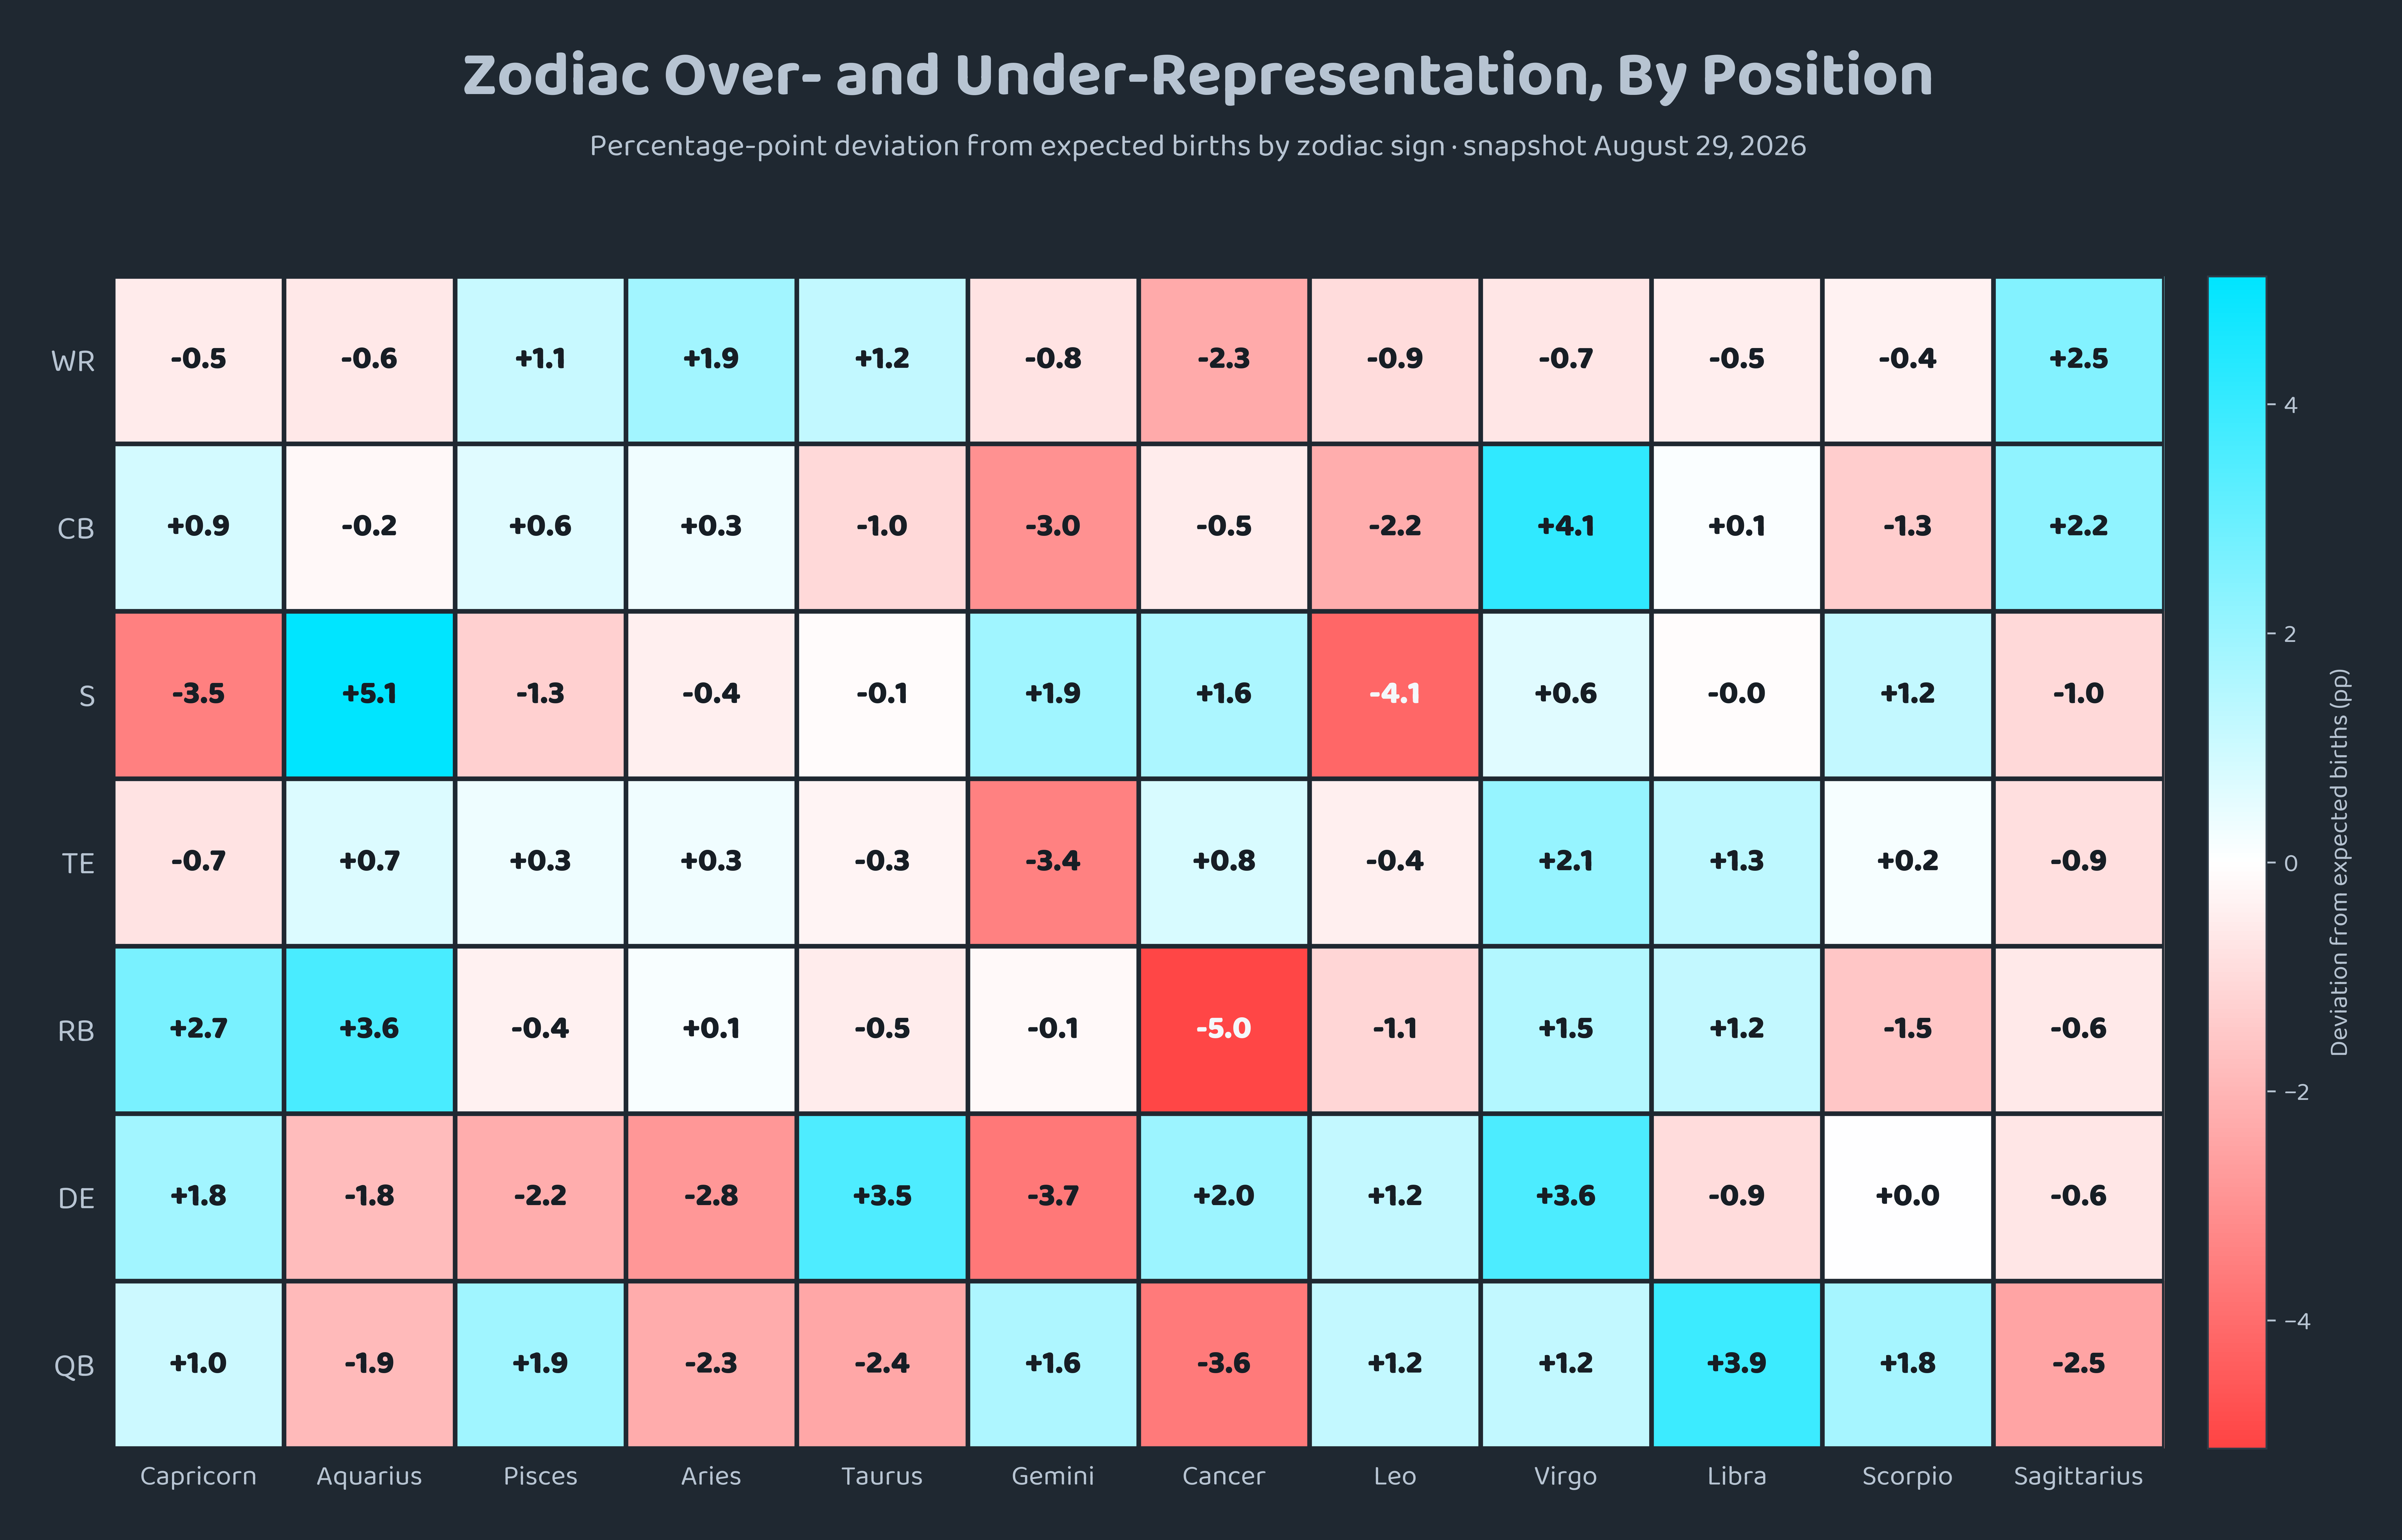

In [68]:
plot_left, plot_right = 0.09, 0.90
title_x = (plot_left + plot_right) / 2

fig.text(title_x, 0.955, "Zodiac Over- and Under-Representation, By Position",
          ha="center", va="top", fontsize=27, fontweight="bold", color=MUTED)
fig.text(title_x, 0.905,
          f"Percentage-point deviation from expected births by zodiac sign · snapshot {snapshot_date}",
          ha="center", va="top", fontsize=13.5, color=MUTED)

fig

## Step 18 — Save

In [69]:
out = FIGURES_DIR / "position-zodiac-deviation-heatmap.png"
fig.savefig(out, dpi=600, facecolor=BG)
print(f"saved -> {out.name}  ({out.stat().st_size / 1024:.0f} KB)")

saved -> position-zodiac-deviation-heatmap.png  (942 KB)
